# IEEE 39 bus : New England

Reseau de test **IEEE 39 bus** (New England) : dix machines synchrones, dont
une grosse machine au bus 39 qui represente le reste du reseau interconnecte,
46 branches et 21 charges, en 345 kV. La machine du bus 31 est le slack. Il
fait apparaitre plusieurs modes inter-zones et c'est le plus gros des reseaux
de test (plus de 400 etats).

Comme pour l'IEEE 14, les transformateurs de la source sont declares comme des
lignes en pu sur une base de tension unique, et les deux charges a Q negatif
(bus 9 : -66,6 Mvar, bus 24 : -92,2 Mvar) deviennent une charge de 1 % de P
plus un shunt capacitif qui ramene le total a la valeur de la source.

```
  39 bus 345 kV, 10 machines aux bus 30 a 39 (31 = slack), 46 branches, 21 charges
```

Base systeme : **100 MVA, 60 Hz**, base de tension unique 345 kV.

Equivalent MATLAB : `matlab/G2Elin_V2/reseaux_test/reseaux_classiques/IEEE39.m`.

### Comment comparer avec MATLAB

| Notebook (Python) | MATLAB |
|---|---|
| `net.run_loadflow()` | `net.Load_flow(Y_DER, false)` |
| `net.build_state_space()` | `net.buildGlobalModel()` |
| tableau modal ci-dessous | `displayModalAnalysis()` (`EigenVal_Table = 1`) |

Le tableau modal reprend les conventions MATLAB : participation
`p_ki = |v_gauche . v_droit|` normalisee par mode, `f_undamp = |lambda|/2pi`,
`f_damp = |Im(lambda)|/2pi`, `zeta = -Re(lambda)/|lambda|`, tri par
`Re(lambda)` decroissant, tous les modes conjugues inclus.

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid import Network  # noqa: E402
from g2egrid.elements import (  # noqa: E402
    GFL1,
    GFL2,
    GFM1,
    GFM2,
    GFM3,
    GFM4,
    IB,
    Bus,
    ILoad,
    Line,
    PLoad,
    RLLoad,
    SynchronousMachine,
    SynchronousMachineTR,
    Transformer,
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "IEEE39"
F_ZOOM = 3.0

f0 = 60.0
Sb = 100e6

Ub = 345e3

# BusType : 1 = slack, 2 = PV, 3 = PQ

Y_DER = [ # [BusID, BusType, V_base, V_pu, Theta_rad,   Pg_W, Qg_var,     Pl_W,   Ql_var]
        ( 1, 3, Ub, 1.0394, 0,      0, 0,  97.6e6,  44.2e6),
        ( 2, 3, Ub, 1.0485, 0,      0, 0,       0,       0),
        ( 3, 3, Ub, 1.0307, 0,      0, 0,   322e6,   2.4e6),
        ( 4, 3, Ub, 1.0045, 0,      0, 0,   500e6,   184e6),
        ( 5, 3, Ub, 1.0060, 0,      0, 0,       0,       0),
        ( 6, 3, Ub, 1.0082, 0,      0, 0,       0,       0),
        ( 7, 3, Ub, 0.9984, 0,      0, 0, 233.8e6,    84e6),
        ( 8, 3, Ub, 0.9979, 0,      0, 0,   522e6, 176.6e6),
        ( 9, 3, Ub, 1.0383, 0,      0, 0,   6.5e6, 0.065e6),
        (10, 3, Ub, 1.0178, 0,      0, 0,       0,       0),
        (11, 3, Ub, 1.0134, 0,      0, 0,       0,       0),
        (12, 3, Ub, 1.0008, 0,      0, 0,  8.53e6,    88e6),
        (13, 3, Ub, 1.0149, 0,      0, 0,       0,       0),
        (14, 3, Ub, 1.0123, 0,      0, 0,       0,       0),
        (15, 3, Ub, 1.0162, 0,      0, 0,   320e6,   153e6),
        (16, 3, Ub, 1.0325, 0,      0, 0,   329e6,  32.3e6),
        (17, 3, Ub, 1.0342, 0,      0, 0,       0,       0),
        (18, 3, Ub, 1.0316, 0,      0, 0,   158e6,    30e6),
        (19, 3, Ub, 1.0501, 0,      0, 0,       0,       0),
        (20, 3, Ub, 0.9910, 0,      0, 0,   680e6,   103e6),
        (21, 3, Ub, 1.0323, 0,      0, 0,   274e6,   115e6),
        (22, 3, Ub, 1.0501, 0,      0, 0,       0,       0),
        (23, 3, Ub, 1.0451, 0,      0, 0, 247.5e6,  84.6e6),
        (24, 3, Ub, 1.0380, 0,      0, 0, 308.6e6, 3.086e6),
        (25, 3, Ub, 1.0577, 0,      0, 0,   224e6,  47.2e6),
        (26, 3, Ub, 1.0526, 0,      0, 0,   139e6,    17e6),
        (27, 3, Ub, 1.0383, 0,      0, 0,   281e6,  75.5e6),
        (28, 3, Ub, 1.0504, 0,      0, 0,   206e6,  27.6e6),
        (29, 3, Ub, 1.0501, 0,      0, 0, 283.5e6,  26.9e6),
        (30, 2, Ub, 1.0499, 0,  250e6, 0,       0,       0),
        (31, 1, Ub, 0.9820, 0,      0, 0,   9.2e6,   4.6e6),
        (32, 2, Ub, 0.9841, 0,  650e6, 0,       0,       0),
        (33, 2, Ub, 0.9972, 0,  632e6, 0,       0,       0),
        (34, 2, Ub, 1.0123, 0,  508e6, 0,       0,       0),
        (35, 2, Ub, 1.0494, 0,  650e6, 0,       0,       0),
        (36, 2, Ub, 1.0636, 0,  560e6, 0,       0,       0),
        (37, 2, Ub, 1.0275, 0,  540e6, 0,       0,       0),
        (38, 2, Ub, 1.0265, 0,  830e6, 0,       0,       0),
        (39, 2, Ub, 1.0300, 0, 1000e6, 0,  1104e6,   250e6),
]

# T_Lines_SI : [ID, From, To, Length_km, R_ohm/km, X_ohm/km, B_S/km]
T_Lines_SI = []

# T_Lines_pu : [ID, From, To, Length_km, R_pu, X_pu, B_pu, Un_V, Sb_VA]
#   R_pu, X_pu, B_pu : valeurs TOTALES de la ligne, en pu sur (Un_V, Sb_VA)
T_Lines_pu = [
    ( 1,  1,  2, 1, 0.0035, 0.0411, 0.6987, Ub, 100e6),
    ( 2,  1, 39, 1, 0.0010, 0.0250, 0.7500, Ub, 100e6),
    ( 3,  2,  3, 1, 0.0013, 0.0151, 0.2572, Ub, 100e6),
    ( 4,  2, 25, 1, 0.0070, 0.0086, 0.1460, Ub, 100e6),
    ( 5,  2, 30, 1, 0.0001, 0.0181, 0.0000, Ub, 100e6),
    ( 6,  3,  4, 1, 0.0013, 0.0213, 0.2214, Ub, 100e6),
    ( 7,  3, 18, 1, 0.0011, 0.0133, 0.2138, Ub, 100e6),
    ( 8,  4,  5, 1, 0.0008, 0.0128, 0.1342, Ub, 100e6),
    ( 9,  4, 14, 1, 0.0008, 0.0129, 0.1382, Ub, 100e6),
    (10,  5,  6, 1, 0.0002, 0.0026, 0.0434, Ub, 100e6),
    (11,  5,  8, 1, 0.0008, 0.0112, 0.1476, Ub, 100e6),
    (12,  6,  7, 1, 0.0006, 0.0092, 0.1130, Ub, 100e6),
    (13,  6, 11, 1, 0.0007, 0.0082, 0.1389, Ub, 100e6),
    (14,  6, 31, 1, 0.0001, 0.0250, 0.0000, Ub, 100e6),
    (15,  7,  8, 1, 0.0004, 0.0046, 0.0780, Ub, 100e6),
    (16,  8,  9, 1, 0.0023, 0.0363, 0.3804, Ub, 100e6),
    (17,  9, 39, 1, 0.0010, 0.0250, 1.2000, Ub, 100e6),
    (18, 10, 11, 1, 0.0004, 0.0043, 0.0729, Ub, 100e6),
    (19, 10, 13, 1, 0.0004, 0.0043, 0.0729, Ub, 100e6),
    (20, 10, 32, 1, 0.0001, 0.0200, 0.0000, Ub, 100e6),
    (21, 12, 11, 1, 0.0016, 0.0435, 0.0000, Ub, 100e6),
    (22, 12, 13, 1, 0.0016, 0.0435, 0.0000, Ub, 100e6),
    (23, 13, 14, 1, 0.0009, 0.0101, 0.1723, Ub, 100e6),
    (24, 14, 15, 1, 0.0018, 0.0217, 0.3660, Ub, 100e6),
    (25, 15, 16, 1, 0.0009, 0.0094, 0.1710, Ub, 100e6),
    (26, 16, 17, 1, 0.0007, 0.0089, 0.1342, Ub, 100e6),
    (27, 16, 19, 1, 0.0016, 0.0195, 0.3040, Ub, 100e6),
    (28, 16, 21, 1, 0.0008, 0.0135, 0.2548, Ub, 100e6),
    (29, 16, 24, 1, 0.0003, 0.0059, 0.0680, Ub, 100e6),
    (30, 17, 18, 1, 0.0007, 0.0082, 0.1319, Ub, 100e6),
    (31, 17, 27, 1, 0.0013, 0.0173, 0.3216, Ub, 100e6),
    (32, 19, 20, 1, 0.0007, 0.0138, 0.0000, Ub, 100e6),
    (33, 19, 33, 1, 0.0007, 0.0142, 0.0000, Ub, 100e6),
    (34, 20, 34, 1, 0.0009, 0.0180, 0.0000, Ub, 100e6),
    (35, 21, 22, 1, 0.0008, 0.0140, 0.2565, Ub, 100e6),
    (36, 22, 23, 1, 0.0006, 0.0096, 0.1846, Ub, 100e6),
    (37, 22, 35, 1, 0.0001, 0.0143, 0.0000, Ub, 100e6),
    (38, 23, 24, 1, 0.0022, 0.0350, 0.3610, Ub, 100e6),
    (39, 23, 36, 1, 0.0005, 0.0272, 0.0000, Ub, 100e6),
    (40, 25, 26, 1, 0.0032, 0.0323, 0.5310, Ub, 100e6),
    (41, 25, 37, 1, 0.0006, 0.0232, 0.0000, Ub, 100e6),
    (42, 26, 27, 1, 0.0014, 0.0147, 0.2396, Ub, 100e6),
    (43, 26, 28, 1, 0.0043, 0.0474, 0.7802, Ub, 100e6),
    (44, 26, 29, 1, 0.0057, 0.0625, 1.0290, Ub, 100e6),
    (45, 28, 29, 1, 0.0014, 0.0151, 0.2490, Ub, 100e6),
    (46, 29, 38, 1, 0.0008, 0.0156, 0.0000, Ub, 100e6),
]

# T_Shunts : [ID, BusID, B_pu]   (compensation shunt propre au bus)
T_Shunts = [
    (1,  9, 0.66665),
    (2, 24, 0.95286),
]

# T_Transfos : [ID, From, To, Sn_VA, U1_V, U2_V, R_pu, X_pu]
T_Transfos = []

# T_IBs : [ID, BusID, Sn_VA, E_pu, theta_deg, R_pu, X_pu]
T_IBs = []

# T_SMs : [ID, BusID, Sn_VA]  ou  [ID, BusID, Sn_VA, Rt_pu, Xt_pu]
T_SMs = [
    ( 1, 30,  300e6),
    ( 2, 31,  800e6),
    ( 3, 32,  700e6),
    ( 4, 33,  700e6),
    ( 5, 34,  600e6),
    ( 6, 35,  700e6),
    ( 7, 36,  600e6),
    ( 8, 37,  600e6),
    ( 9, 38,  900e6),
    (10, 39, 1100e6),
]
SM_PARAMS = {}

# T_GFM1s a T_GFM4s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFM1s = []
T_GFM2s = []
T_GFM3s = []
T_GFM4s = []

# T_GFL1s, T_GFL2s : [ID, BusID, Sn_VA, Vdc_V]  ou  [ID, BusID, Sn_VA, Vdc_V, Rt_pu, Xt_pu]
T_GFL1s = []
T_GFL2s = []

# T_Loads : [ID, BusID, P_W, Q_var, Type]   (charges SPECIALES)
#   Type : 'I' = courant constant, 'P' = puissance constante. Les charges
#   classiques (R-L) viennent des colonnes Pl_W, Ql_var de Y_DER ; une charge
#   speciale s'y ajoute, load flow compris. Exemple : (1, 7, 0.5e6, 0.1e6, 'P'),
T_Loads = []

In [3]:
# --- bases de tension par bus, lues dans Y_DER ---
UN = {int(r[0]): r[2] for r in Y_DER}

# --- capacite shunt de chaque bus : moitie de la charge des lignes qui y
#     aboutissent (schema en pi), comme C_half = B_pu/2 dans Network.m. Un bus
#     qui n'en recoit aucune devient un noeud ALGEBRIQUE a resistance de
#     causalite R = 100 pu (Node.m / setResistor(100)). ---
Cbus = {int(r[0]): 0.0 for r in Y_DER}
for _id, i, j, km, _r, _x, b_km in T_Lines_SI:
    b_pu = b_km * km * (UN[i] ** 2 / Sb)
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
for _id, i, j, _km, _r, _x, b_pu, Un, Sb_l in T_Lines_pu:
    b_pu = b_pu * (UN[i] ** 2 / Sb) / (Un ** 2 / Sb_l)  # base de la ligne -> base systeme
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
# compensation shunt propre a un bus (banc de condensateurs), qui s'ajoute a
# la charge capacitive des lignes. MATLAB n'a pas de colonne pour cela dans
# Y_DER : d'ou une table a part, plutot qu'une colonne en plus.
for _id, b, B_pu in T_Shunts:
    Cbus[b] += B_pu

# --- charges speciales de T_Loads : leur consommation s'ajoute a celle de
#     Y_DER dans le load flow ---
CHARGES_SPECIALES = {"I": ILoad, "P": PLoad}
S_spec = {int(r[0]): [0.0, 0.0] for r in Y_DER}
for _id, b, P, Q, typ in T_Loads:
    if typ not in CHARGES_SPECIALES:
        raise ValueError(f"T_Loads, charge {_id} : type '{typ}' inconnu ('I' ou 'P')")
    S_spec[b][0] += P
    S_spec[b][1] += Q

# --- assemblage du reseau
net = Network(f0=f0, Sb=Sb)

for bid, btype, Un, Vpu, theta, Pg, Qg, Pl, Ql in Y_DER:  # Y_DER
    net.add(
        Bus(
            int(bid),
            Un,
            btype=int(btype),
            V=Vpu,
            theta=theta,
            Pg=Pg,
            Qg=Qg,
            Pl=Pl + S_spec[int(bid)][0],
            Ql=Ql + S_spec[int(bid)][1],
            C=Cbus[int(bid)],
        )
    )

for lid, i, j, km, r_km, x_km, _b in T_Lines_SI:  # T_Lines_SI
    ZB = UN[i] ** 2 / Sb
    net.add(
        Line(
            f"L{int(lid)}_{i}_{j}", i, j, R=r_km * km / ZB, X=x_km * km / ZB, wb=net.wb
        )
    )

for lid, i, j, _km, r_pu, x_pu, _b, Un, Sb_l in T_Lines_pu:  # T_Lines_pu
    k = (Un ** 2 / Sb_l) / (UN[i] ** 2 / Sb)  # base de la ligne -> base systeme
    net.add(Line(f"L{int(lid)}_{i}_{j}", i, j, R=r_pu * k, X=x_pu * k, wb=net.wb))

# Une prise hors nominal se declare par U1_V/U2_V, comme dans Network.m :
# n = (U1/U2)/(Un_i/Un_j), egal a 1 quand U1, U2 sont les tensions des bus.
for tid, i, j, Sn, U1, U2, R, X in T_Transfos:  # T_Transfos
    k = (Sb / Sn) * (U1 / UN[i]) ** 2  # base du transfo -> base systeme
    n = (U1 / U2) / (UN[i] / UN[j])
    net.add(Transformer(f"T{int(tid)}_{i}_{j}", i, j, R=R * k, X=X * k, wb=net.wb, n=n))

for _id, b, Sn, _E, _th, R, X in T_IBs:  # T_IBs
    net.add(IB(f"IB{b}", b, R=R, X=X, wb=net.wb, Sn=Sn, Sb=Sb))

# Colonnes optionnelles Rt_pu, Xt_pu des tables de DER : transfo de
# raccordement INTEGRE a l'equipement. Sans elles, la machine n'a pas de
# transfo (a declarer dans T_Transfos) et le convertisseur garde son filtre
# R2/L2 par defaut.
for _id, b, Sn, *Tr in T_SMs:  # T_SMs
    if Tr:
        net.add(SynchronousMachineTR(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, Rt=Tr[0], Lt=Tr[1], **SM_PARAMS))
    else:
        net.add(SynchronousMachine(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **SM_PARAMS))

for T_GFM, GFM in ((T_GFM1s, GFM1), (T_GFM2s, GFM2), (T_GFM3s, GFM3), (T_GFM4s, GFM4)):  # T_GFM1s a T_GFM4s
    for _id, b, Sn, _Vdc, *Tr in T_GFM:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFM(f"GFM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFM_PARAMS | tr)))

for T_GFL, GFL in ((T_GFL1s, GFL1), (T_GFL2s, GFL2)):  # T_GFL1s, T_GFL2s
    for _id, b, Sn, _Vdc, *Tr in T_GFL:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFL(f"GFL{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFL_PARAMS | tr)))

# Charges classiques : colonnes Pl_W, Ql_var de Y_DER -> charge R-L a
# impedance constante (GenericLoad.m). Une inductance ne peut pas consommer
# un reactif negatif ou nul : condensateur dans T_Shunts, ou charge speciale.
n_rl = 0
for bid, *_, Pl, Ql in Y_DER:  # Y_DER : charges classiques
    if Pl == 0 and Ql == 0:
        continue
    if Ql <= 0:
        raise ValueError(
            f"bus {int(bid)} : Ql = {Ql:g} var. Une charge R-L demande Ql > 0 ; "
            "declarer le condensateur dans T_Shunts ou la charge dans T_Loads ('P' ou 'I')"
        )
    net.add(RLLoad(f"Load{int(bid)}", int(bid), P=Pl / Sb, Q=Ql / Sb, wb=net.wb))
    n_rl += 1

for lid, b, P, Q, typ in T_Loads:  # T_Loads : charges speciales
    net.add(CHARGES_SPECIALES[typ](f"Load{typ}{int(lid)}_{b}", b, P=P / Sb, Q=Q / Sb))

n_gfm = len(T_GFM1s) + len(T_GFM2s) + len(T_GFM3s) + len(T_GFM4s)
print(
    f"{NOM_RESEAU} : {len(Y_DER)} bus, "
    f"{len(T_Lines_SI) + len(T_Lines_pu)} ligne(s), {len(T_Transfos)} transfo(s), "
    f"{len(T_IBs)} bus infini, {len(T_SMs)} machine(s), {n_gfm} GFM, "
    f"{len(T_GFL1s) + len(T_GFL2s)} GFL, {n_rl} charge(s) R-L, "
    f"{len(T_Loads)} charge(s) speciale(s)"
)

IEEE39 : 39 bus, 46 ligne(s), 0 transfo(s), 0 bus infini, 10 machine(s), 0 GFM, 0 GFL, 21 charge(s) R-L, 0 charge(s) speciale(s)


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 6 iterations (mismatch 1.01e-13)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0279     -14.1488      -0.9760      -0.4420
   2     1.0189     -10.1557      -0.0000      -0.0000
   3     0.9916     -12.7528      -3.2200      -0.0240
   4     0.9551     -13.0358      -5.0000      -1.8400
   5     0.9542     -11.3791      -0.0000      -0.0000
   6     0.9553     -10.4894       0.0000      -0.0000
   7     0.9482     -13.1156      -2.3380      -0.8400
   8     0.9494     -13.7691      -5.2200      -1.7660
   9     1.0188     -14.7787      -0.0650      -0.0006
  10     0.9621      -8.0233       0.0000      -0.0000
  11     0.9585      -8.8708      -0.0000       0.0000
  12     0.9390      -8.9662      -0.0853      -0.8800
  13     0.9604      -8.8908      -0.0000      -0.0000
  14     0.9610     -10.9232       0.0000       0.0000
  15     0.9695     -11.7185      -3.2000      -1.5300
  16   

## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 402 etats, 63 entrees, 351 sorties | max Re(lambda)=+5.807e-11>

402 etats, 63 entrees, 351 sorties
stable : True   max Re(lambda) = +5.8067e-11

Etats par element :
  bus1           2 : vd, vq
  bus2           2 : vd, vq
  bus3           2 : vd, vq
  bus4           2 : vd, vq
  bus5           2 : vd, vq
  bus6           2 : vd, vq
  bus7           2 : vd, vq
  bus8           2 : vd, vq
  bus9           2 : vd, vq
  bus10          2 : vd, vq
  bus11          2 : vd, vq
  bus13          2 : vd, vq
  bus14          2 : vd, vq
  bus15          2 : vd, vq
  bus16          2 : vd, vq
  bus17          2 : vd, vq
  bus18          2 : vd, vq
  bus19          2 : vd, vq
  bus21          2 : vd, vq
  bus22          2 : vd, vq
  bus23          2 : vd, vq
  bus24          2 : vd, vq
  bus25          2 : vd, vq
  bus26          2 : vd, vq
  bus27          2 : vd, vq
  bus28          2 : vd, vq
  bus29          2 : vd, vq
  bus39          2 : vd, vq
  L1_1_2         2 : i_d, i_q
  L2_1_3

### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
245,-8.743293e-13,0.000000,1.391538e-13,0.000000,0.000000,SM39.theta,15.068701,SM38.theta,13.001147,SM31.theta,11.472053
340,-1.769719e-01,0.000000,2.816595e-02,0.000000,100.000000,SM39.vpss,19.784125,SM38.vpss,9.512357,SM35.vpss,8.511798
357,-1.865408e-01,0.000000,2.968889e-02,0.000000,100.000000,SM36.vpss,38.868368,SM38.vpss,27.476319,SM35.vpss,24.597132
358,-1.866436e-01,0.000000,2.970525e-02,0.000000,100.000000,SM38.vpss,44.836861,SM31.vpss,23.779598,SM32.vpss,14.032207
359,-1.867774e-01,0.000000,2.972655e-02,0.000000,100.000000,SM34.vpss,46.758102,SM33.vpss,22.751708,SM31.vpss,12.423198
...,...,...,...,...,...,...,...,...,...,...,...
4,-6.436089e+05,0.000000,1.024335e+05,0.000000,100.000000,L5_2_30.i_q,64.872847,SM30.phi_d,19.118385,L5_2_30.i_d,15.979328
2,-1.771272e+06,376.991118,2.819067e+05,60.000000,99.999998,L22_12_13.i_q,24.463722,L22_12_13.i_d,24.463722,L21_12_11.i_d,24.463656
3,-1.771272e+06,-376.991118,2.819067e+05,60.000000,99.999998,L22_12_13.i_q,24.463722,L22_12_13.i_d,24.463722,L21_12_11.i_d,24.463656


### 2.2 Carte des valeurs propres

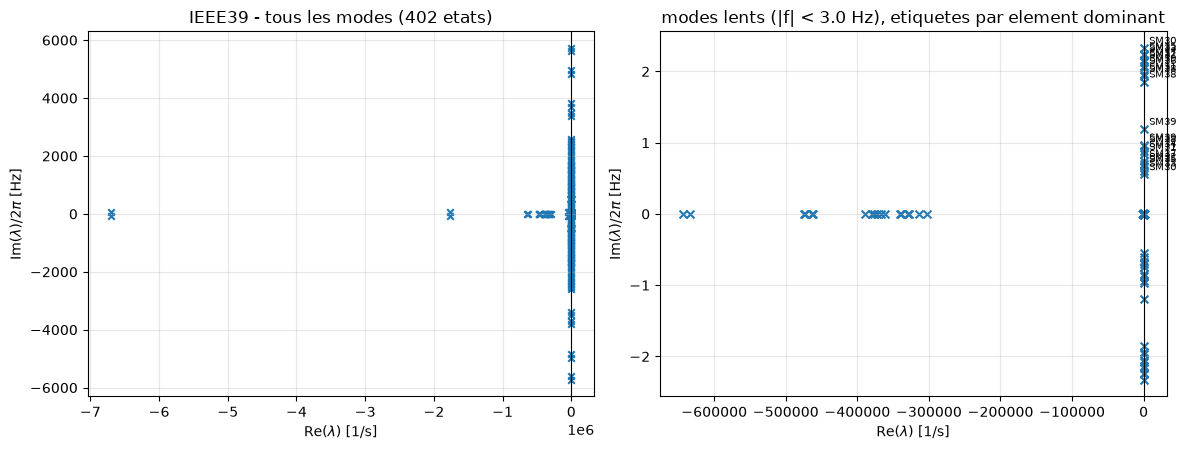

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()